# CeranaWatch — results notebook

This notebook re-creates the main results of the CeranaWatch app from the **raw hive recordings**, so they can be shown and checked live.
It uses the same sound rules and the same model numbers as the Android app.

| Part | What it shows |
|---|---|
| 1 | The 70 recordings and their labels |
| 2 | The app's hive check on every recording (outcome, listening time) |
| 3 | **Live demo**: one hive, then the same hive with talking added — old rule vs the new bee-sound filter |
| 4 | Bee-sound filter test: 57 kinds of other sound, on apiaries and sounds it never heard |
| 5 | Strength models: honest test on unseen hives, and why higher scores came from the apiary |
| 6 | On-phone learning at a new apiary: before and after the clip-level change |
| 7 | Summary table |

**How to run:** `Runtime → Run all`. Set `QUICK = True` for a fast run (about 10–15 minutes, fewer repeats, numbers close to the thesis),
or `QUICK = False` for the full numbers (about 40–60 minutes). Results are cached in `WORK`, so a second run is much faster.

In [1]:
# ---------- settings ----------
import os
QUICK = os.environ.get('CW_QUICK', '1') == '1'     # True = fast run; False = full numbers
IN_COLAB = False
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except Exception:
    pass
# folder with the original hive recordings (.m4a or .wav, names like S01H01_MEDIUM_1007.m4a)
RAW_DIR = os.environ.get('CW_RAW_DIR', '/content/drive/MyDrive/bee_data/raw')
# where downloads and cached results are kept (in Drive, so a second run is fast)
WORK = os.environ.get('CW_WORK', '/content/drive/MyDrive/bee_data/results_cache' if IN_COLAB else '/content/work')
YAMNET_FILE = os.environ.get('CW_YAMNET', os.path.join(WORK, 'yamnet.tflite'))
YAMNET_URL = 'https://storage.googleapis.com/mediapipe-models/audio_classifier/yamnet/float32/1/yamnet.tflite'
os.makedirs(WORK, exist_ok=True)
print('QUICK =', QUICK, '| recordings:', RAW_DIR, '| work folder:', WORK)

In [2]:
# ---------- libraries ----------
import re, io, json, zlib, base64, glob, time, subprocess, urllib.request, collections, warnings
import numpy as np, pandas as pd, soundfile as sf
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
warnings.filterwarnings('ignore')
try:
    import tensorflow as tf
    Interpreter = tf.lite.Interpreter
except Exception:
    try:
        from ai_edge_litert.interpreter import Interpreter
    except Exception:
        subprocess.run(['pip', 'install', '-q', 'ai-edge-litert'], check=True)
        from ai_edge_litert.interpreter import Interpreter
from IPython.display import Audio, display
SR = 16000
CLASSES = ['medium', 'strong', 'weak']
RNG_SEED = 0
print('ready')

ready


## Field labels and the app's model numbers
The labels come from the field forms (one row per hive). The model numbers are copied from the app
(`ModelData.kt` for the strength model, `BeeGateData.kt` for the bee-sound filter).

In [3]:
LABELS_CSV = '''hive,strength,site,district,flow,colony_age,days_since_opened,problem,problem_type,weather_note
S01H01,medium,S01,Kegalle,outside,6-12 months,1-7 days ago,yes,predator_wasp,
S01H02,medium,S01,Kegalle,outside,6-12 months,1-7 days ago,no,none,
S01H03,medium,S01,Kegalle,outside,6-12 months,Today,no,none,
S01H04,medium,S01,Kegalle,outside,6-12 months,1-7 days ago,no,none,
S01H05,medium,S01,Kegalle,outside,6-12 months,1-7 days ago,no,none,
S01H06,medium,S01,Kegalle,outside,6-12 months,1-7 days ago,no,none,sunny
S01H07,medium,S01,Kegalle,outside,6-12 months,1-7 days ago,yes,predator_wasp,
S01H08,medium,S01,Kegalle,outside,6-12 months,1-7 days ago,no,none,
S01H09,medium,S01,Kegalle,outside,6-12 months,1-7 days ago,no,none,
S01H10,medium,S01,Kegalle,outside,6-12 months,1-7 days ago,no,none,
S01H11,strong,S01,Kegalle,outside,6-12 months,1-7 days ago,yes,queenless,
S01H12,medium,S01,Kegalle,outside,6-12 months,1-7 days ago,no,none,
S01H13,medium,S01,Kegalle,outside,6-12 months,1-7 days ago,no,none,
S01H14,medium,S01,Kegalle,outside,unknown,1-7 days ago,no,none,
S01H15,medium,S01,Kegalle,outside,6-12 months,1-7 days ago,no,none,
S02H01,medium,S02,Gampaha,outside,6-12 months,1-7 days ago,no,none,
S02H02,medium,S02,Gampaha,outside,6-12 months,1-4 weeks ago,no,none,
S02H03,medium,S02,Gampaha,outside,6-12 months,1-4 weeks ago,no,none,
S02H05,strong,S02,Gampaha,outside,6-12 months,1-4 weeks ago,no,none,
S02H04,medium,S02,Gampaha,outside,6-12 months,1-4 weeks ago,no,none,
S02H06,medium,S02,Gampaha,outside,6-12 months,1-4 weeks ago,no,none,
S02H07,medium,S02,Gampaha,outside,6-12 months,1-4 weeks ago,no,none,
S02H08,medium,S02,Gampaha,outside,6-12 months,1-4 weeks ago,no,none,
S02H09,medium,S02,Gampaha,outside,6-12 months,1-4 weeks ago,no,none,
S02H10,medium,S02,Gampaha,outside,6-12 months,1-4 weeks ago,no,none,
S02H11,medium,S02,Gampaha,outside,6-12 months,1-4 weeks ago,no,none,
S02H12,medium,S02,Gampaha,outside,6-12 months,1-4 weeks ago,no,none,
S02H13,medium,S02,Gampaha,outside,6-12 months,1-4 weeks ago,no,none,
S02H14,medium,S02,Gampaha,outside,1-2 years,1-4 weeks ago,no,none,
S02H15,weak,S02,Gampaha,outside,1-2 years,Today,yes,waxmoth,
S02H16,weak,S02,Gampaha,outside,1-2 years,Today,no,none,
S03H01,weak,S03,Badulla,during,Over 2 years,Over a month,no,none,rainy
S03H02,weak,S03,Badulla,during,1-2 years,Over a month,no,none,rainy
S03H03,strong,S03,Badulla,during,Over 2 years,Over a month,no,none,
S03H04,strong,S03,Badulla,during,Over 2 years,Over a month,no,none,
S03H05,strong,S03,Badulla,during,Over 2 years,Over a month,no,none,
S03H06,strong,S03,Badulla,during,Over 2 years,Over a month,no,none,
S03H07,strong,S03,Badulla,during,Over 2 years,Over a month,no,none,
S03H08,strong,S03,Badulla,during,Over 2 years,Over a month,no,none,
S03H09,strong,S03,Badulla,during,Over 2 years,Over a month,no,none,
S03H10,strong,S03,Badulla,during,Over 2 years,Over a month,no,none,
S04H01,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H02,weak,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H03,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H04,weak,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H06,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H05,strong,S04,Badulla,during,1-2 years,Over a month,yes,waxmoth,
S04H07,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H08,strong,S04,Badulla,during,1-2 years,Over a month,yes,queenless,
S04H09,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H10,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H11,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H12,weak,S04,Badulla,during,1-2 years,Over a month,yes,queenless,
S04H13,weak,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H14,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H15,weak,S04,Badulla,during,1-2 years,Over a month,yes,queenless,
S04H16,weak,S04,Badulla,during,1-2 years,Over a month,yes,queenless,
S04H17,weak,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H18,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H19,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H20,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H21,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H22,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H23,weak,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H24,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H25,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H26,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H27,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H28,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H29,strong,S04,Badulla,during,1-2 years,Over a month,no,none,
S04H30,strong,S04,Badulla,during,1-2 years,Over a month,yes,queenless,'''

labels = pd.read_csv(io.StringIO(LABELS_CSV), keep_default_na=False, dtype=str).set_index('hive')
MODELS = json.loads(zlib.decompress(base64.b64decode('...')))
APP = {k: np.array(v) if k != 'classes' else v for k, v in MODELS['app'].items()}
GATE = MODELS['gate']
GATE_MEAN, GATE_SCALE, GATE_COEF = np.array(GATE['mean']), np.array(GATE['scale']), np.array(GATE['coef'])
print(len(labels), 'hives in the label table; strength model', APP['coef'].shape, '; bee-sound filter', GATE_COEF.shape[0], 'numbers')

71 hives in the label table; strength model (3, 121) ; bee-sound filter 1089 numbers


## The app's sound rules, written in Python
Each function below copies one part of the app (file names in brackets), so the notebook gives the same answers as the phone.

In [4]:
def hann(n): return 0.5 - 0.5 * np.cos(2 * np.pi * np.arange(n) / n)          # periodic Hann (Dsp.hann)

def power_frames(x, nfft, hop):                                                 # Dsp.powerFrames
    n = 1 + (len(x) - nfft) // hop
    idx = np.arange(nfft)[None, :] + hop * np.arange(n)[:, None]
    return np.abs(np.fft.rfft(x[idx] * hann(nfft), axis=1)) ** 2

F1024 = np.arange(513) * SR / 1024
F2048 = np.arange(1025) * SR / 2048
BEE_BAND = np.where((F2048 >= 60) & (F2048 <= 1000))[0]

def speech_share(x):                                                            # Dsp.speechShare: the old clean-sound rule
    P = power_frames(x, 1024, 512)
    lo_b = P[:, (F1024 >= 100) & (F1024 <= 600)].sum(1); hi_b = P[:, (F1024 >= 900) & (F1024 <= 4000)].sum(1)
    k = int(0.5 * SR / 512); n = len(lo_b) // k
    lo = lo_b[:n * k].reshape(n, k).sum(1); hi = hi_b[:n * k].reshape(n, k).sum(1)
    return float(np.median(hi / (lo + hi + 1e-12)))

def bee_shape(x):                                                               # Dsp.beeSpectrumDb + shapeOf
    P = power_frames(x, 2048, 512)
    s = 10 * np.log10(P[:, BEE_BAND].mean(0) + 1e-12)
    return s - s.mean()

def app_vote(shape):                                                            # Analyzer.classify (70-hive strength model)
    z = (shape - APP['mean']) / APP['scale']
    return int(np.argmax(APP['intercept'] + APP['coef'] @ z))

def db(x): return 20 * np.log10(np.sqrt(np.mean(x.astype(np.float64) ** 2)) + 1e-9)

BAND_RANGES = GATE['bands']
EPS = 1e-10
def sound_measures(x):                                                          # BeeGate.soundMeasures (46 numbers)
    P = power_frames(x, 1024, 512)
    E = np.stack([P[:, a:b + 1].sum(1) for a, b in BAND_RANGES], 1) + EPS
    mean_db = 10 * np.log10(E.mean(0)); shape = mean_db - mean_db.mean()
    var = (10 * np.log10(E)).std(0)
    tot = 10 * np.log10(E.sum(1)); med = np.median(tot)
    f = [tot.std(), np.mean(tot < med - 6), np.mean(np.abs(np.diff(tot)))]
    for lo, hi in ((100, 1000), (1000, 4000)):
        Pb = P[:, (F1024 >= lo) & (F1024 < hi)] + EPS
        f.append(np.mean(np.exp(np.mean(np.log(Pb), 1)) / np.mean(Pb, 1)))
    Pn = P / (P.sum(1, keepdims=True) + EPS)
    f.append(np.mean(np.sum(np.abs(np.diff(Pn, axis=0)), 1)))
    return np.concatenate([shape, var, np.array(f)])

# YAMNet (Google, Apache 2.0): 521 sound types for 0.975 s of sound
if not os.path.exists(YAMNET_FILE):
    urllib.request.urlretrieve(YAMNET_URL, YAMNET_FILE)
_yam = Interpreter(model_path=YAMNET_FILE); _yam.allocate_tensors()
_yin = _yam.get_input_details()[0]
_yout = [d for d in _yam.get_output_details() if d['shape'][-1] == 521][0]['index']
STARTS = [0, 8100, 16200, 24300, 32400]
def yamnet_clip(x):                                                             # BeeGate.windows + YamNet.scores
    x = np.clip(x * (0.05 / (np.sqrt(np.mean(x ** 2)) + 1e-9)), -1, 1).astype(np.float32)
    out = []
    for s in STARTS:
        _yam.set_tensor(_yin['index'], x[s:s + 15600].reshape(_yin['shape'])); _yam.invoke()
        out.append(_yam.get_tensor(_yout).reshape(-1)[:521].copy())
    return np.stack(out)

def gate_features(yam5, x):                                                     # BeeGate.features (1089 numbers)
    return np.concatenate([np.log(yam5.mean(0) + 1e-4), np.log(yam5.max(0) + 1e-4), sound_measures(x), [speech_share(x)]])

def gate_logit(F):                                                              # BeeGate.score
    return ((F - GATE_MEAN) / GATE_SCALE) @ GATE_COEF + GATE['intercept']

print('sound rules ready; YAMNet input', _yin['shape'])

sound rules ready; YAMNet input [15600]


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


## Part 1 — the recordings
Every recording is converted to 16 kHz mono (the phone records the same way). The phone skips the first 9 seconds
(the colony is disturbed when the lid is lifted) and then judges the sound in 3-second clips.

In [5]:
def load_audio(path):
    tmp = os.path.join(WORK, '_tmp.wav')
    subprocess.run(['ffmpeg', '-nostdin', '-loglevel', 'error', '-y', '-i', path, '-ac', '1', '-ar', str(SR), '-sample_fmt', 's16', tmp], check=True)
    return sf.read(tmp, dtype='int16')[0]

CACHE = os.path.join(WORK, 'hive_clips.npz')
if os.path.exists(CACHE):
    C = dict(np.load(CACHE, allow_pickle=True)); print('loaded from cache')
else:
    files = {}
    for f in sorted(glob.glob(os.path.join(RAW_DIR, '*'))):
        name = os.path.basename(f)
        m = re.match(r'(S\d\dH\d\d)', name)
        if not m or 'same' in name.lower() or not name.lower().endswith(('.m4a', '.wav', '.mp3')): continue
        files.setdefault(m.group(1), f)
    rows = collections.defaultdict(list); t0 = time.time()
    for i, (hive, f) in enumerate(sorted(files.items())):
        x = load_audio(f)
        if len(x) < 30 * SR: print('skipped (too short):', hive); continue
        for k in range((len(x) - 9 * SR) // (3 * SR)):
            c = x[9 * SR + k * 3 * SR: 9 * SR + (k + 1) * 3 * SR]; xf = c.astype(np.float32) / 32768
            y5 = yamnet_clip(xf); F = gate_features(y5, xf)
            rows['hive'].append(hive); rows['k'].append(k); rows['db'].append(db(xf)); rows['share'].append(F[-1])
            rows['shape'].append(bee_shape(xf)); rows['gate'].append(gate_logit(F)); rows['yam'].append(F[:1042]); rows['measures'].append(F[1042:1088])
        if i % 10 == 0: print(f'{i + 1}/{len(files)} recordings, {time.time() - t0:.0f} s')
    C = {k: np.array(v) for k, v in rows.items()}
    np.savez_compressed(CACHE, **C)
C['site'] = np.array([h[:3] for h in C['hive']]); C['strength'] = np.array([labels.loc[h, 'strength'] for h in C['hive']])
C['old_ok'] = (C['db'] >= -75) & (C['share'] <= 0.30)
C['gate_ok'] = C['old_ok'] & (C['gate'] >= GATE['logit_threshold'])
hives = sorted(set(C['hive']))
H = labels.loc[hives]
print(len(hives), 'hives,', len(C['hive']), 'clips of 3 s')
display(pd.crosstab(H['site'], H['strength'], margins=True))

loaded from cache


70 hives, 4026 clips of 3 s


strength,medium,strong,weak,All
site,,,,
S01,14,1,0,15
S02,13,1,2,16
S03,0,8,2,10
S04,0,21,8,29
All,27,31,12,70


## Part 2 — the app's hive check on every recording
The phone keeps a 3-second clip only if it is not silent (below −75 dB), passes the old rule, and (new) passes the bee-sound filter.
It stops when it has 20 clean clips (one minute of bee sound), or after 180 seconds. Then it votes on the colony strength.

--- old rule only ---
outcome
READING                 55
UNCLEAR                  9
VERY QUIET               3
NOT ENOUGH BEE SOUND     3
one minute of bee sound collected: 56 of 70 hives;  median listening 90 s
strength = field label: 48 of 64  (best case: the model was trained on these hives)

--- with bee-sound filter ---
outcome
READING                 53
UNCLEAR                 10
NOT ENOUGH BEE SOUND     4
VERY QUIET               3
one minute of bee sound collected: 54 of 70 hives;  median listening 92 s
strength = field label: 47 of 63  (best case: the model was trained on these hives)



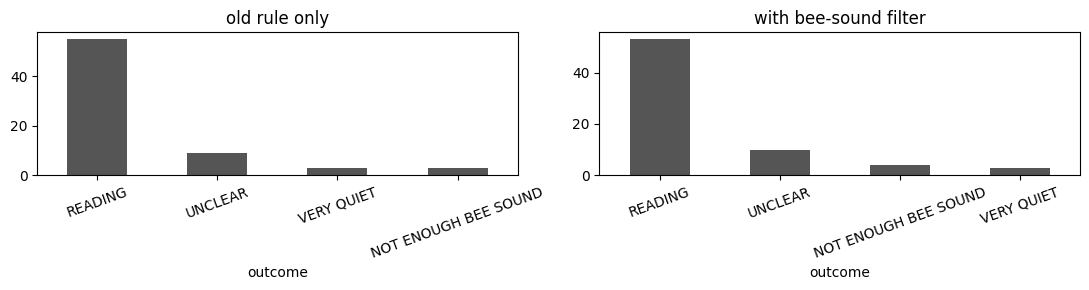

In [6]:
def phone_check(hive, use_gate):
    m = C['hive'] == hive
    order = np.argsort(C['k'][m]); idx = np.where(m)[0][order][:57]        # 180 s of listening = 9 s + 57 clips
    kept, other, silent, judged = [], 0, 0, 0
    for i in idx:
        judged += 1
        if C['db'][i] < -75: silent += 1
        elif C['share'][i] > 0.30 or (use_gate and C['gate'][i] < GATE['logit_threshold']): other += 1
        else: kept.append(i)
        if len(kept) >= 20: break
    seconds = 9 + 3 * judged
    if not kept: return dict(outcome='VERY QUIET' if silent > other else 'NOT ENOUGH BEE SOUND', strength='', seconds=seconds, kept=0)
    if np.mean(C['db'][kept]) < -65: out = 'VERY QUIET'
    elif len(kept) < 8: out = 'NOT ENOUGH BEE SOUND'
    else:
        votes = np.bincount([app_vote(C['shape'][i]) for i in kept], minlength=3)
        out = 'READING' if votes.max() >= 0.5 * len(kept) else 'UNCLEAR'
        return dict(outcome=out, strength=CLASSES[int(np.argmax(votes))], seconds=seconds, kept=len(kept))
    return dict(outcome=out, strength='', seconds=seconds, kept=len(kept))

R2 = {}
for name, g in (('old rule only', False), ('with bee-sound filter', True)):
    df = pd.DataFrame([dict(hive=h, label=labels.loc[h, 'strength'], **phone_check(h, g)) for h in hives])
    R2[name] = df
    print(f'--- {name} ---')
    print(df['outcome'].value_counts().to_string())
    got = df[df['strength'] != '']
    print(f"one minute of bee sound collected: {(df['kept'] >= 20).sum()} of {len(df)} hives;  median listening {df['seconds'].median():.0f} s")
    print(f"strength = field label: {(got['strength'] == got['label']).sum()} of {len(got)}  (best case: the model was trained on these hives)\n")
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for a, (name, df) in zip(ax, R2.items()):
    df['outcome'].value_counts().plot.bar(ax=a, color='#555'); a.set_title(name); a.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

## Part 3 — live demo: does the app keep only bee sound?
First one real hive recording. Then the same recording with **talking** added in the middle (as loud as the bees).
The table shows what happens to every 3-second clip: kept as bee sound, or thrown away.

In [7]:
DEMO_HIVE = 'S04H09'          # change to any hive name
SPEECH_URLS = ['https://raw.githubusercontent.com/openai/whisper/main/tests/jfk.flac'] + \
    [f'https://raw.githubusercontent.com/microsoft/MS-SNSD/master/clean_test/clnsp{i}.wav' for i in range(71, 81)]
def download(url, folder, quiet404=True):
    os.makedirs(folder, exist_ok=True); out = os.path.join(folder, url.split('/')[-1])
    for attempt in range(3):
        if os.path.exists(out): return out
        try:
            urllib.request.urlretrieve(url, out + '.part'); os.replace(out + '.part', out); return out
        except urllib.error.HTTPError as e:
            if e.code == 404:
                if not quiet404: print('not found:', url)
                return None                       # some MS-SNSD file numbers do not exist; that is expected
        except Exception as e:
            time.sleep(1)
    print('could not download', url); return None
speech = np.concatenate([load_audio(p).astype(np.float32) / 32768 for p in [download(u, os.path.join(WORK, 'speech_demo')) for u in SPEECH_URLS] if p])
f = [p for p in glob.glob(os.path.join(RAW_DIR, DEMO_HIVE + '*')) if 'same' not in p.lower()][0]
x = load_audio(f).astype(np.float32) / 32768
y = x.copy()
a, b = 39 * SR, 84 * SR                                     # talking from 39 s to 84 s (clips 10 to 24)
s = speech[:b - a] if len(speech) >= b - a else np.resize(speech, b - a)
y[a:b] += s * np.sqrt(np.mean(x[a:b] ** 2) / (np.mean(s ** 2) + 1e-12))
y = np.clip(y, -1, 1)
def judge_all(sig):
    rows = []
    for k in range(min(30, (len(sig) - 9 * SR) // (3 * SR))):
        c = sig[9 * SR + k * 3 * SR: 9 * SR + (k + 1) * 3 * SR]
        F = gate_features(yamnet_clip(c), c)
        old = 'silent' if db(c) < -75 else ('thrown away' if F[-1] > 0.30 else 'KEPT')
        new = old if old != 'KEPT' else ('KEPT' if gate_logit(F) >= GATE['logit_threshold'] else 'thrown away (filter)')
        rows.append(dict(clip=f'{9 + 3 * k}-{12 + 3 * k} s', talking='yes' if a <= 9 * SR + k * 3 * SR < b else '', old_rule=old, with_filter=new))
    return pd.DataFrame(rows)
print('Original recording:'); display(Audio(x[:60 * SR], rate=SR))
print('With talking added from 39 s to 84 s:'); display(Audio(y[30 * SR:90 * SR], rate=SR))
DEMO = judge_all(y)
display(DEMO)
demo_talk = DEMO[DEMO['talking'] == 'yes']
print(f"Clips with talking: old rule kept {(demo_talk['old_rule'] == 'KEPT').sum()} of {len(demo_talk)};  with the filter kept {(demo_talk['with_filter'] == 'KEPT').sum()} of {len(demo_talk)}")

Original recording:


[Audio clip removed from the public copy]

With talking added from 39 s to 84 s:


[Audio clip removed from the public copy]

,clip,talking,old_rule,with_filter
0,9-12 s,,KEPT,KEPT
1,12-15 s,,KEPT,KEPT
2,15-18 s,,KEPT,KEPT
3,18-21 s,,KEPT,KEPT
4,21-24 s,,KEPT,KEPT
5,24-27 s,,KEPT,KEPT
6,27-30 s,,KEPT,KEPT
7,30-33 s,,KEPT,KEPT
8,33-36 s,,KEPT,KEPT
9,36-39 s,,KEPT,KEPT


Clips with talking: old rule kept 13 of 15;  with the filter kept 1 of 15


## Part 4 — bee-sound filter test (57 kinds of other sound)
Sounds come from two public sets: **ESC-50** (50 kinds of environmental sound, CC BY-NC) and **MS-SNSD** (speech, crowds, traffic; MIT).
The filter is trained **leaving one apiary out** each time, and tested on sound recordings that were never used in training.

In [8]:
import csv as _csv
NOISE_DIR = os.path.join(WORK, 'nonbee')
os.makedirs(NOISE_DIR, exist_ok=True)
meta = download('https://raw.githubusercontent.com/karolpiczak/ESC-50/master/meta/esc50.csv', NOISE_DIR)
esc = list(_csv.DictReader(open(meta)))
if QUICK: esc = [r for r in esc if r['fold'] in ('1', '2', '3')]              # quick run: 3 of the 5 folds
def get_esc(r):
    return download(f"https://raw.githubusercontent.com/karolpiczak/ESC-50/master/audio/{r['filename']}", os.path.join(NOISE_DIR, 'esc'))
with ThreadPoolExecutor(16) as ex: esc_paths = list(ex.map(get_esc, esc))
S = 'https://raw.githubusercontent.com/microsoft/MS-SNSD/master/'
snsd = [(f'{S}clean_test/clnsp{i}.wav', 'talking', 'train' if i <= 70 else 'test') for i in range(1, 101)]
for key, kind in [('Babble', 'crowd_babble'), ('Neighbor', 'people_next_door'), ('AirportAnnouncements', 'loudspeaker'), ('Typing', 'typing'), ('Traffic', 'traffic'), ('AirConditioner', 'air_conditioner')]:
    for i in range(1, 7):
        for part in ('noise_train', 'noise_test'):
            snsd.append((f'{S}{part}/{key}_{i}.wav', kind, 'train' if part == 'noise_train' else 'test'))
def get_snsd(t):
    p = download(t[0], os.path.join(NOISE_DIR, 'snsd', t[0].split('/')[-2])); return (p, t[1], t[2])
with ThreadPoolExecutor(16) as ex: snsd = [t for t in ex.map(get_snsd, snsd) if t[0]]
print(len([p for p in esc_paths if p]), 'ESC-50 files and', len(snsd), 'MS-SNSD files ready')

NCACHE = os.path.join(WORK, 'nonbee_windows' + ('_quick' if QUICK else '') + '.npz')
if os.path.exists(NCACHE):
    N = dict(np.load(NCACHE, allow_pickle=True)); print('loaded from cache')
else:
    items = [(r['category'], 'test' if r['fold'] == '1' else 'train', p) for r, p in zip(esc, esc_paths) if p]
    for p, k, s in snsd:
        if k in ('traffic', 'air_conditioner'):             # only one recording each: first 60 % for training, the rest for testing
            items += [(k, 'train', p + '#first60'), (k, 'test', p + '#last40')]
        else:
            items.append((k, s, p))
    rows = collections.defaultdict(list)
    for kind, split, p in items:
        part = p.split('#')[1] if '#' in p else ''
        x = load_audio(p.split('#')[0]).astype(np.float32) / 32768
        if part == 'first60': x = x[:int(len(x) * 0.6)]
        if part == 'last40': x = x[int(len(x) * 0.6):]
        starts = [0, 2 * SR] if len(x) <= 5.5 * SR else range(0, len(x) - 3 * SR + 1, 3 * SR)
        for s0 in starts:
            c = x[s0:s0 + 3 * SR]
            if len(c) < 3 * SR or np.sqrt(np.mean(c ** 2)) < 1e-4: continue
            c = c / np.sqrt(np.mean(c ** 2)) * 0.01
            rows['kind'].append(kind); rows['split'].append(split); rows['audio'].append((np.clip(c, -1, 1) * 32767).astype(np.int16))
    N = {k: np.array(v) for k, v in rows.items()}
    np.savez_compressed(NCACHE, **N)
print(len(N['kind']), 'windows of other sound,', len(set(N['kind'])), 'kinds')

2000 ESC-50 files and 149 MS-SNSD files ready


5154 windows of other sound, 57 kinds


In [9]:
# YAMNet scores and filter numbers for: other sounds alone, and mixed into hive clips
MCACHE = os.path.join(WORK, 'filter_test' + ('_quick' if QUICK else '') + '.npz')
def mix(h, n, snr_db):
    return np.clip(h + n * np.sqrt((np.mean(h ** 2) + 1e-12) / (np.mean(n ** 2) + 1e-12) * 10 ** (snr_db / 10)), -1, 1)
hive_audio = {}                                                     # all 70 recordings kept in memory (about 400 MB)
def hive_clip(i):
    h = C['hive'][i]
    if h not in hive_audio:
        f = [p for p in glob.glob(os.path.join(RAW_DIR, h + '*')) if 'same' not in p.lower()][0]
        hive_audio[h] = load_audio(f)
    k = C['k'][i]; return hive_audio[h][9 * SR + k * 3 * SR: 9 * SR + (k + 1) * 3 * SR].astype(np.float32) / 32768
if os.path.exists(MCACHE):
    M = dict(np.load(MCACHE, allow_pickle=True)); print('loaded from cache')
else:
    rng = np.random.default_rng(1); t0 = time.time()
    NA = N['audio'].astype(np.float32) / 32767 * 0.3
    tr_n = np.where(N['split'] == 'train')[0]; te_n = np.where(N['split'] == 'test')[0]
    Fn = np.array([gate_features(yamnet_clip(a), a) for a in NA]); print('other sounds done', round(time.time() - t0), 's')
    per = 1 if QUICK else 3
    mt_h, mt_snr, Fmt = [], [], []
    for i in np.argsort(C['hive'], kind='stable'):                       # hive by hive, so each recording is read once
        h = hive_clip(i)
        snrs = [rng.uniform(-30, -20)] + [rng.uniform(-6, 10) for _ in range(per - 1 if per > 1 else 1)]
        for snr in snrs:
            m = mix(h, NA[rng.choice(tr_n)] / 0.3, snr); mt_h.append(i); mt_snr.append(snr); Fmt.append(gate_features(yamnet_clip(m), m))
    print('training mixtures done', round(time.time() - t0), 's')
    te_h, te_kind, te_snr, Fte = [], [], [], []
    for kind in sorted(set(N['kind'][te_n])):
        idx = te_n[N['kind'][te_n] == kind]
        for snr in (0, -10):
            for _ in range(12 if QUICK else 40):
                i = rng.integers(len(C['hive'])); j = rng.choice(idx)
                m = mix(hive_clip(i), NA[j] / 0.3, snr); te_h.append(i); te_kind.append(kind); te_snr.append(snr); Fte.append(gate_features(yamnet_clip(m), m))
    print('test mixtures done', round(time.time() - t0), 's')
    M = dict(Fn=np.array(Fn), mt_h=np.array(mt_h), mt_snr=np.array(mt_snr), Fmt=np.array(Fmt), te_h=np.array(te_h), te_kind=np.array(te_kind), te_snr=np.array(te_snr), Fte=np.array(Fte))
    np.savez_compressed(MCACHE, **M)

other sounds done 79 s


training mixtures done 345 s


test mixtures done 413 s


In [10]:
# Leave one apiary out: train the filter without that apiary's hives, test on its hives and on held-out sounds
Fh = np.hstack([C['yam'], C['measures'], C['share'][:, None]])
site_of = lambda idx: C['site'][idx]
res = collections.defaultdict(list)
for s in ['S01', 'S02', 'S03', 'S04']:
    trh = C['site'] != s; mt_ok = site_of(M['mt_h']) != s; tr_n = N['split'] == 'train'
    Xp = np.vstack([Fh[trh], M['Fmt'][mt_ok & (M['mt_snr'] < -15)]]); Xn = np.vstack([M['Fn'][tr_n], M['Fmt'][mt_ok & (M['mt_snr'] > -15)]])
    sc = StandardScaler().fit(np.vstack([Xp, Xn]))
    clf = LogisticRegression(max_iter=3000, C=0.05, class_weight='balanced').fit(sc.transform(np.vstack([Xp, Xn])), np.r_[np.ones(len(Xp)), np.zeros(len(Xn))])
    z = lambda F: sc.transform(F) @ clf.coef_[0] + clf.intercept_[0]
    thr = np.quantile(z(Fh[trh]), 0.05)
    te = ~trh
    res['bee_old'] += list(C['old_ok'][te]); res['bee_new'] += list(C['old_ok'][te] & (z(Fh[te]) >= thr))
    te_n = np.where(N['split'] == 'test')[0]
    for j, zz in zip(te_n, z(M['Fn'][te_n])):
        old_reject = M['Fn'][j][-1] > 0.30
        res[('alone', N['kind'][j], 'old')].append(old_reject); res[('alone', N['kind'][j], 'new')].append(old_reject or zz < thr)
    mm = np.where(site_of(M['te_h']) == s)[0]
    for q, zz in zip(mm, z(M['Fte'][mm])):
        old_reject = M['Fte'][q][-1] > 0.30
        key = ('mix%d' % M['te_snr'][q], M['te_kind'][q])
        res[key + ('old',)].append(old_reject); res[key + ('new',)].append(old_reject or zz < thr)
rows = []
for kind in sorted(set(N['kind'][N['split'] == 'test'])):
    r = dict(sound=kind)
    for t in ('alone', 'mix0', 'mix-10'):
        r[f'{t} old'] = np.mean(res[(t, kind, 'old')]); r[f'{t} new'] = np.mean(res[(t, kind, 'new')])
    rows.append(r)
R4 = pd.DataFrame(rows).set_index('sound')
print(f"Clean hive clips kept (apiary not seen in training): old rule {np.mean(res['bee_old']):.0%}, old rule + filter {np.mean(res['bee_new']):.0%}")
print('Share of other sound THROWN AWAY (higher is better). "mix0" = as loud as the bees, "mix-10" = 10 dB quieter:')
display((R4 * 100).round(0).astype(int).loc[[k for k in ['talking', 'crowd_babble', 'people_next_door', 'loudspeaker', 'traffic', 'engine', 'train', 'car_horn', 'chirping_birds', 'insects', 'wind', 'rain', 'dog', 'rooster'] if k in R4.index]])
print('Average over all', len(R4), 'kinds:'); display((R4.mean() * 100).round(0).astype(int).to_frame('%').T)

Clean hive clips kept (apiary not seen in training): old rule 65%, old rule + filter 53%
Share of other sound THROWN AWAY (higher is better). "mix0" = as loud as the bees, "mix-10" = 10 dB quieter:


,alone old,alone new,mix0 old,mix0 new,mix-10 old,mix-10 new
sound,,,,,,
talking,10,100,10,88,20,60
crowd_babble,28,100,20,100,30,85
people_next_door,16,100,22,82,35,65
loudspeaker,15,100,28,90,20,80
traffic,8,100,12,72,32,55
engine,31,81,22,50,38,55
train,0,100,0,88,20,70
car_horn,58,98,52,82,60,85
chirping_birds,88,100,82,90,38,65


Average over all 57 kinds:


,alone old,alone new,mix0 old,mix0 new,mix-10 old,mix-10 new
%,55,96,51,82,41,67


## Part 5 — strength models: what "optimization" really changes
Every model is tested on **hives it never heard** (hive-blocked cross-validation).
Two extra checks show whether a better score is real:
* **Strong vs weak inside S04**: one apiary, so the apiary cannot help.
* **Site guess**: how often "medium" is answered exactly for hives at S01/S02 (where all medium hives are) — a sign the model learned the apiary.

In [11]:
keep = C['gate_ok']
cnt = collections.Counter(C['hive'][keep]); keep = keep & np.array([cnt[h] >= 8 for h in C['hive']])
hv, yv = C['hive'][keep], C['strength'][keep]
FEATS = {'shape': C['shape'][keep], 'all': np.hstack([C['shape'], C['yam'], C['measures']])[keep]}
HH = np.array(sorted(set(hv))); HY = np.array([yv[hv == h][0] for h in HH]); HS = np.array([h[:3] for h in HH])
REPEATS = 3 if QUICK else 10
def lr(Cc=1.0): return make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=Cc, class_weight='balanced'))
def rf(seed): return RandomForestClassifier(300, class_weight='balanced_subsample', min_samples_leaf=5, n_jobs=-1, random_state=seed)
MODELS_5 = {
    'A  app now: bee-band shape, logistic regression, vote': ('shape', lambda s: lr(1.0), 'vote'),
    'B  same, average the chances': ('shape', lambda s: lr(1.0), 'mean'),
    'F  bee-band shape, random forest': ('shape', rf, 'mean'),
    'I  shape + YAMNet + measures, logistic regression': ('all', lambda s: lr(0.03), 'mean'),
    'K  shape + YAMNet + measures, random forest': ('all', rf, 'mean'),
}
rows = []
for name, (fk, make, mode) in MODELS_5.items():
    X = FEATS[fk]; bas, s04, siteg = [], [], []; t0 = time.time()
    for r in range(REPEATS):
        pred = {}
        for tr, te in StratifiedGroupKFold(5, shuffle=True, random_state=r).split(X, yv, hv):
            m = make(r).fit(X[tr], yv[tr]); P = m.predict_proba(X[te])
            for h in set(hv[te]):
                p = P[hv[te] == h]
                pred[h] = CLASSES[int(np.argmax(np.bincount(p.argmax(1), minlength=3)))] if mode == 'vote' else CLASSES[int(np.argmax(p.mean(0)))]
        pv = np.array([pred[h] for h in HH])
        bas.append(balanced_accuracy_score(HY, pv))
        sel = (HS == 'S04') & np.isin(HY, ['strong', 'weak'])
        s04.append(balanced_accuracy_score(HY[sel], pv[sel]))
        siteg.append(np.mean((pv == 'medium') == np.isin(HS, ['S01', 'S02'])))
    rows.append(dict(model=name, **{'unseen hives (BA)': f'{np.mean(bas):.2f} ± {np.std(bas):.2f}', 'strong vs weak inside S04': round(np.mean(s04), 2), 'site guess': round(np.mean(siteg), 2)}))
    print(f'{name}: done in {time.time() - t0:.0f} s')
R5 = pd.DataFrame(rows).set_index('model'); display(R5)
print('Guessing: BA 0.33 (3 classes), 0.50 for strong vs weak.')

A  app now: bee-band shape, logistic regression, vote: done in 9 s


B  same, average the chances: done in 10 s


F  bee-band shape, random forest: done in 142 s


I  shape + YAMNet + measures, logistic regression: done in 112 s


K  shape + YAMNet + measures, random forest: done in 148 s


,unseen hives (BA),strong vs weak inside S04,site guess
model,,,
"A app now: bee-band shape, logistic regression, vote",0.49 ± 0.03,0.48,0.65
"B same, average the chances",0.50 ± 0.04,0.51,0.68
"F bee-band shape, random forest",0.60 ± 0.03,0.46,0.76
"I shape + YAMNet + measures, logistic regression",0.58 ± 0.04,0.46,0.82
"K shape + YAMNet + measures, random forest",0.61 ± 0.03,0.45,0.79


Guessing: BA 0.33 (3 classes), 0.50 for strong vs weak.


In [12]:
# Strength INSIDE one apiary: train and test only on S04 (strong vs weak), hive-blocked
sel = keep & (C['site'] == 'S04') & np.isin(C['strength'], ['strong', 'weak'])
hv4 = C['hive'][sel]; y4 = (C['strength'][sel] == 'weak').astype(int); X4 = C['shape'][sel]
H4 = np.array(sorted(set(hv4))); Y4 = np.array([y4[hv4 == h][0] for h in H4])
aucs = []
for r in range(5 if QUICK else 20):
    sc4 = {}
    for tr, te in StratifiedGroupKFold(4, shuffle=True, random_state=r).split(X4, y4, hv4):
        p = lr(0.1).fit(X4[tr], y4[tr]).predict_proba(X4[te])[:, 1]
        for h in set(hv4[te]): sc4[h] = p[hv4[te] == h].mean()
    aucs.append(roc_auc_score(Y4, [sc4[h] for h in H4]))
print(f'Inside S04 ({len(H4)} hives, {Y4.sum()} weak): AUC {np.mean(aucs):.2f} ± {np.std(aucs):.2f}   (guessing 0.50)')

Inside S04 (27 hives, 7 weak): AUC 0.74 ± 0.04   (guessing 0.50)


## Part 6 — on-phone learning at a new apiary
A beekeeper at apiary S04 checks each hive once and answers "How strong is this colony?".
Before each answer, the app guesses from earlier answers only (predict first, then learn).
The 70-hive model used as the starting point is trained **without** S04.

In [13]:
def softmax(z): z = z - z.max(-1, keepdims=True); e = np.exp(z); return e / e.sum(-1, keepdims=True)
def fit_gd(X, y, W0, b0, lam=0.1, steps=300, rate=0.1):                       # Learner.fit (same maths as the app)
    X = np.asarray(X); y = np.asarray(y); n = len(y); K = W0.shape[0]
    cnts = np.bincount(y, minlength=K); wt = n / ((cnts > 0).sum() * cnts[y]); Y = np.eye(K)[y]
    W = W0.copy(); b = b0.copy()
    for _ in range(steps):
        G = wt[:, None] * (softmax(X @ W.T + b) - Y) / n
        W -= rate * (G.T @ X + lam * (W - W0)); b -= rate * (G.sum(0) + 0.1 * lam * (b - b0))
    return W, b
def details_x(h):                                                               # Learner.detailFeatures
    r = labels.loc[h]; x = np.zeros(8)
    x[0 if r['flow'] == 'during' else 1] = 1
    k = {'sunny': 2, 'rainy': 4}.get(r['weather_note'])
    if k: x[k] = 1
    d = {'Over a month': 45, '1-7 days ago': 4, '1-4 weeks ago': 15, 'Today': 0}.get(r['days_since_opened']); a = {'1-2 years': 18, '6-12 months': 9, 'Over 2 years': 30}.get(r['colony_age'])
    if d is not None: x[6] = min(d, 60) / 30
    if a is not None: x[7] = min(a, 36) / 12
    return x
SITE = 'S04'
ok = C['gate_ok'] & (C['site'] != SITE)
bsc = StandardScaler().fit(C['shape'][ok]); blr = LogisticRegression(max_iter=5000, C=1.0, class_weight='balanced').fit(bsc.transform(C['shape'][ok]), C['strength'][ok])
assert list(blr.classes_) == CLASSES
W0 = np.hstack([blr.coef_, np.zeros((3, 8))]); b0 = blr.intercept_.copy()
site_hives = [h for h in hives if h.startswith(SITE) and (C['gate_ok'] & (C['hive'] == h)).sum() >= 8]
rng = np.random.default_rng(0); out = {k: ([], []) for k in ['before: one averaged sound per check', 'now: every clean clip', 'always the most common answer']}
for rep in range(5 if QUICK else 20):
    order = rng.permutation(site_hives); D = []
    for h in order:
        cl = C['shape'][C['gate_ok'] & (C['hive'] == h)]; pick = cl[rng.choice(len(cl), min(20, len(cl)), replace=False)]
        rows_ = np.array([np.r_[bsc.transform(p[None])[0], details_x(h)] for p in pick])
        D.append((np.r_[bsc.transform(pick.mean(0)[None])[0], details_x(h)], rows_, CLASSES.index(labels.loc[h, 'strength'])))
    for t in range(3, len(D)):
        truth = D[t][2]
        W, b = fit_gd([d[0] for d in D[:t]], [d[2] for d in D[:t]], W0, b0)
        out['before: one averaged sound per check'][0].append(truth); out['before: one averaged sound per check'][1].append(int(np.argmax(D[t][0] @ W.T + b)))
        W, b = fit_gd([r for d in D[:t] for r in d[1]], [d[2] for d in D[:t] for _ in d[1]], W0, b0)
        out['now: every clean clip'][0].append(truth); out['now: every clean clip'][1].append(int(np.argmax(softmax(D[t][1] @ W.T + b).mean(0))))
        out['always the most common answer'][0].append(truth); out['always the most common answer'][1].append(int(np.argmax(np.bincount([d[2] for d in D[:t]], minlength=3))))
R6 = pd.DataFrame([dict(method=k, accuracy=round(np.mean(np.array(t) == np.array(p)), 2), balanced_accuracy=round(balanced_accuracy_score(t, p), 2)) for k, (t, p) in out.items()]).set_index('method')
print(f'New apiary {SITE}: {len(site_hives)} hives'); display(R6)

New apiary S04: 27 hives


,accuracy,balanced_accuracy
method,,
before: one averaged sound per check,0.65,0.55
now: every clean clip,0.67,0.59
always the most common answer,0.72,0.49


## Part 7 — summary

In [14]:
df_old, df_new = R2['old rule only'], R2['with bee-sound filter']
summary = pd.DataFrame([
    ['Hive check: hives with 1 minute of bee sound (old / with filter)', f"{(df_old['kept'] >= 20).sum()} / {(df_new['kept'] >= 20).sum()} of {len(df_old)}"],
    ['Live demo: clips with talking kept (old / with filter)', f"{(demo_talk['old_rule'] == 'KEPT').sum()} / {(demo_talk['with_filter'] == 'KEPT').sum()} of {len(demo_talk)}"],
    ['Other sounds alone thrown away, average (old / with filter)', f"{R4['alone old'].mean():.0%} / {R4['alone new'].mean():.0%}"],
    ['Other sounds as loud as the bees thrown away (old / with filter)', f"{R4['mix0 old'].mean():.0%} / {R4['mix0 new'].mean():.0%}"],
    ['Strength, app model, unseen hives (BA)', R5.iloc[0, 0]],
    ['Strength, best-looking model (random forest, all features)', R5.iloc[-1, 0] + f"  but inside S04: {R5.iloc[-1, 1]}"],
    ['Strength inside one apiary (S04, AUC)', f'{np.mean(aucs):.2f}'],
    ['On-phone learning at a new apiary, BA (before / now)', f"{R6.iloc[0, 1]} / {R6.iloc[1, 1]}"],
], columns=['result', 'value']).set_index('result')
display(summary)

,value
result,
Hive check: hives with 1 minute of bee sound (old / with filter),56 / 54 of 70
Live demo: clips with talking kept (old / with filter),13 / 1 of 15
"Other sounds alone thrown away, average (old / with filter)",55% / 96%
Other sounds as loud as the bees thrown away (old / with filter),51% / 82%
"Strength, app model, unseen hives (BA)",0.49 ± 0.03
"Strength, best-looking model (random forest, all features)",0.61 ± 0.03 but inside S04: 0.45
"Strength inside one apiary (S04, AUC)",0.74
"On-phone learning at a new apiary, BA (before / now)",0.55 / 0.59


## Part 8 — the hive device's bee detector, trained with the device's own microphone (11 Oct 2026)

**Why:** inside a house, with no bees, the device sometimes said "bee sound". The detector was trained on phone recordings; the device's INMP441 microphone and a house sound different.

**What the device now does (program 2.1):**
* says "bees" only when **3 of the last 4 readings** pass (a colony hums all the time; house sounds come and go);
* can be **taught** from the app: *No bees here* / *Bees here*. It fits its last layer to the place, and sends the 50 numbers of every taught window to Firebase (`/trainfeatures`).

**This part** reads those numbers and trains the whole detector again, with an honest test:
* hive recall on apiaries the model never heard (leave one apiary out),
* other sounds (57 kinds) it never heard,
* the device's own newest 30% of taught windows, kept out of training.

**Before you run it:** copy `device_features_v2.npz` (in `APP/results_notebook`) to Google Drive → `MyDrive/bee_data/`. Teach the device first (Live screen → *No bees here*, and at a hive *Bees here*).
At the end it saves a new **BeeDetect.h** — put it in the `CeranaNode` folder (replace the old one) and upload to the ESP32.

In [ ]:
# ---------- Part 8a: load the training numbers and the device's own sounds ----------
import os, json, time, urllib.request, numpy as np, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
FIREBASE_URL = 'https://YOUR-PROJECT-default-rtdb.REGION.firebasedatabase.app'   # the same address as in the device
HIVE_NAME = 'H01'                                                                         # the same name as in the device
cands = [os.path.join(WORK, 'device_features_v2.npz'), '/content/drive/MyDrive/bee_data/device_features_v2.npz',
         '/content/device_features_v2.npz', 'device_features_v2.npz']
DEV_NPZ = next((p for p in cands if os.path.exists(p)), None)
assert DEV_NPZ, 'Copy device_features_v2.npz (APP/results_notebook) to Google Drive: MyDrive/bee_data/ , then run this cell again.'
D = np.load(DEV_NPZ)
BASE = json.loads(str(D['base_model']))

def fb_get(path):
    with urllib.request.urlopen(FIREBASE_URL + path, timeout=60) as r:
        return json.loads(r.read().decode('utf-8'))

try:
    raw = fb_get(f'/trainfeatures/{HIVE_NAME}.json') or {}
except Exception as e:
    print('Could not read the device data from Firebase:', e)
    raw = {}
# teaching sessions: readings with the same label, less than 2 minutes apart
DROP_SESSIONS = []        # write session numbers here to leave them out, e.g. [2, 3] if "Bees here" was pressed away from the bees
sessions, last = [], None
for key in sorted(raw):
    r = raw[key]
    t, lab = r.get('t', 0), r.get('label', '')
    if last is None or lab != last[0] or t - last[1] > 120:
        sessions.append({'label': lab, 'start': t, 'records': []})
    sessions[-1]['records'].append(r); last = (lab, t)
rows8a = []
DF, DY, DT = [], [], []
for i, sn in enumerate(sessions, 1):
    probs = [p for r in sn['records'] for p in r.get('p', [])]
    when = time.strftime('%d %b %H:%M', time.gmtime(sn['start'] + 5.5 * 3600)) if sn['start'] > 1.6e9 else '?'
    rows8a.append({'session': i, 'label': 'bees here' if sn['label'] == 'hive' else 'no bees here', 'start (Sri Lanka time)': when,
                   'windows': sum(len(r.get('f', [])) for r in sn['records']),
                   'average bee chance heard': round(float(np.mean(probs)), 2) if probs else None, 'used': i not in DROP_SESSIONS})
    if i in DROP_SESSIONS: continue
    for r in sn['records']:
        for f in r.get('f', []):
            if isinstance(f, list) and len(f) == 50:
                DF.append(f); DY.append(1 if sn['label'] == 'hive' else 0); DT.append(r.get('t', 0))
DF, DY, DT = np.array(DF, float).reshape(-1, 50), np.array(DY, int), np.array(DT)
if rows8a:
    display(pd.DataFrame(rows8a).set_index('session'))
    print('Check the table: a "bees here" session must have been done right at the bees. If not, put its number in DROP_SESSIONS and run this cell again.')
print(f"Training numbers: {len(D['FH'])} hive windows (70 hives), {len(D['FN'])} other-sound windows, "
      f"{len(D['FS'])} synthetic room sounds, {len(D['MX'])} hive+noise mixtures")
print(f'From the device {HIVE_NAME}: {int((DY == 0).sum())} windows taught as "no bees here", {int((DY == 1).sum())} as "bees here"')
if len(DY) == 0:
    print('No device data yet: Part 8b still tests the detector, and 8c makes the same detector again. Teach the device first for a better one.')

In [ ]:
# ---------- Part 8b: is a detector trained with the device's own sounds better? (honest test) ----------
def mlp(X, y, seed=0):
    sc = StandardScaler().fit(X)
    clf = MLPClassifier(hidden_layer_sizes=(16,), alpha=1e-3, max_iter=3000, random_state=seed).fit(sc.transform(X), y)
    return dict(mean=sc.mean_.tolist(), scale=sc.scale_.tolist(), W1=clf.coefs_[0].tolist(), b1=clf.intercepts_[0].tolist(),
                W2=clf.coefs_[1][:, 0].tolist(), b2=float(clf.intercepts_[1][0]), bands=BASE['bands'], threshold=0.5)

def hidden(m, X):
    Z = (np.asarray(X, float) - np.array(m['mean'])) / np.array(m['scale'])
    return np.maximum(0, Z @ np.array(m['W1']) + np.array(m['b1']))

def prob(m, X):
    return 1 / (1 + np.exp(-(hidden(m, X) @ np.array(m['W2']) + m['b2'])))

def presence(p_windows):
    """windows in time order -> share of 10-second readings (3 windows) reported as bees by the device's 3-of-4 rule"""
    on, hist, out = False, [], []
    for i in range(0, len(p_windows) - 2, 3):
        hist = (hist + [np.mean(p_windows[i:i + 3]) >= 0.5])[-4:]
        c = sum(hist)
        if not on and c >= 3: on = True
        elif on and c <= 1: on = False
        out.append(on)
    return np.mean(out) if out else np.nan

FH, FN, FS, MX = D['FH'], D['FN'], D['FS'], D['MX']
site, hive, k = D['site'], D['hive'], D['k']
train_n = D['split'] == 'train'
dev_test = np.zeros(len(DY), bool)                 # the newest 30% of each kind of device window are kept for testing
for lab in (0, 1):
    idx = np.where(DY == lab)[0]; idx = idx[np.argsort(DT[idx], kind='stable')]
    dev_test[idx[int(len(idx) * 0.7):]] = True
DEV_W = 5                                           # each device window counts 5 times (there are few of them)

def train_set(exclude_site=None, with_device=False, device_rows=None):
    Xp = [FH[site != exclude_site], MX[D['mix_site'] != exclude_site]]
    Xn = [FN[train_n], FS[:len(FS) // 2]]
    if with_device and len(DY):
        rows = ~dev_test if device_rows is None else device_rows
        Xp += [DF[rows & (DY == 1)]] * DEV_W
        Xn += [DF[rows & (DY == 0)]] * DEV_W
    Xp, Xn = np.vstack(Xp), np.vstack(Xn)
    return np.vstack([Xp, Xn]), np.r_[np.ones(len(Xp)), np.zeros(len(Xn))]

def report(name, models_by_site, m_all):
    rates = []
    for s, m in models_by_site.items():
        for h in sorted(set(hive[site == s])):
            idx = np.where(hive == h)[0]; idx = idx[np.argsort(k[idx])]
            rates.append(presence(prob(m, FH[idx])))
    pn = prob(m_all, FN[~train_n]); kinds = D['kind'][~train_n]
    row = {'model': name,
           'hive readings reported as bees (unseen apiaries)': round(float(np.nanmean(rates)), 3),
           'other-sound readings reported as bees (57 kinds)': round(float(np.nanmean([presence(pn[kinds == kk]) for kk in sorted(set(kinds))])), 3)}
    if len(DY):
        pdv = prob(m_all, DF[dev_test])
        for lab, col in [(0, 'device "no bees" windows called bees (newest 30%)'), (1, 'device "bees" windows called bees (newest 30%)')]:
            sel = DY[dev_test] == lab
            row[col] = round(float(np.mean(pdv[sel] >= 0.5)), 3) if sel.any() else None
    return row

t0 = time.time(); rows = []
for name, with_dev in [('A: detector without device data', False), ("B: detector with the device's own sounds", True)]:
    if with_dev and not len(DY): continue
    per_site = {s: mlp(*train_set(s, with_dev)) for s in ['S01', 'S02', 'S03', 'S04']}
    rows.append(report(name, per_site, mlp(*train_set(None, with_dev))))
R8 = pd.DataFrame(rows).set_index('model')
display(R8)
print(f'({time.time() - t0:.0f} s) "hive readings": higher is better. "other sounds" and "no bees windows": lower is better.')

In [ ]:
# ---------- Part 8c: the new detector for the device (BeeDetect.h) ----------
use_device = len(DY) > 0
NEW = mlp(*train_set(None, use_device, device_rows=np.ones(len(DY), bool)))
rng = np.random.default_rng(7)
def spread(groups, n):                              # examples spread over all hives / all sound kinds
    keys = sorted(set(groups)); per = int(np.ceil(n / len(keys))); pick = []
    for kk in keys:
        idx = np.where(groups == kk)[0]; pick += list(rng.choice(idx, min(per, len(idx)), replace=False))
    pick = np.array(pick); rng.shuffle(pick); return pick[:n]
FO = np.vstack([FN, FS]); okind = np.r_[D['kind'], np.array(['syn_' + s for s in D['skind']])]
store_bee = hidden(NEW, FH[spread(hive, 240)]); store_other = hidden(NEW, FO[spread(okind, 240)])   # kept on the device for teaching

def num(v):
    t = f'{v:.9g}'
    return t if ('.' in t or 'e' in t) else t + '.0'
def arr(name, vals, per=8):
    vals = [float(v) for v in np.ravel(vals)]
    return (f'static const float {name}[{len(vals)}] = {{\n' +
            ''.join('  ' + ', '.join(num(v) + 'f' for v in vals[i:i + per]) + ',\n' for i in range(0, len(vals), per)) + '};\n')

model_name = time.strftime('colab %d %b %Y') + (f' (70 hives + {len(DY)} device windows)' if use_device else ' (70 hives)')
last = R8.iloc[-1]
results = '// Test (Colab Part 8): ' + '; '.join(f'{c} = {v}' for c, v in last.items() if v is not None)
header = str(D['template'])
for key, val in {
    '@@MODEL_NAME@@': model_name, '@@RESULTS@@': results, '@@THRESHOLD@@': '0.5',
    '@@BAND_LO@@': ', '.join(str(b[0]) for b in NEW['bands']), '@@BAND_HI@@': ', '.join(str(b[1]) for b in NEW['bands']),
    '@@ARRAYS@@': arr('BD_MEAN', NEW['mean']) + '\n' + arr('BD_SCALE', NEW['scale']) + '\n' + arr('BD_W1', np.ravel(NEW['W1'])) + '\n' +
                  arr('BD_B1', NEW['b1']) + '\n' + arr('BD_W2', NEW['W2']) + 'static const float BD_B2 = ' + num(NEW['b2']) + 'f;\n\n' +
                  '// hidden-layer values of stored examples, used when the device is taught (see fineTune)\n' +
                  arr('BD_STORE_BEE', store_bee) + '\n' + arr('BD_STORE_OTHER', store_other)}.items():
    header = header.replace(key, val)
assert '@@' not in header
out = os.path.join(WORK, 'BeeDetect.h')
open(out, 'w').write(header)
print(f'Saved {out} ({len(header) // 1024} KB).')
print('Next: put it in the CeranaNode folder (replace the old BeeDetect.h), upload to the ESP32, then teach "No bees here" once more.')
print('RESULTS ' + json.dumps({'model': model_name, **{c: v for c, v in last.items()}}))
if IN_COLAB:
    from google.colab import files
    files.download(out)